# лабораторная работа 3

в работе реализуются модульная полносвязная сеть, batch normalization, dropout и трехслойная сверточная сеть. для функции потерь используется стандартная softmax cross entropy из задания. дополнительная кастомная функция потерь не вводится.


## подготовка

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from scripts.data_utils import get_cifar10_data
from scripts.gradient_check import eval_numerical_gradient
from scripts.gradient_check import eval_numerical_gradient_array
from scripts.layers import affine_forward
from scripts.layers import affine_backward
from scripts.layers import relu_forward
from scripts.layers import relu_backward
from scripts.layers import batchnorm_forward
from scripts.layers import batchnorm_backward
from scripts.layers import dropout_forward
from scripts.layers import dropout_backward
from scripts.layers import conv_forward_naive
from scripts.layers import conv_backward_naive
from scripts.layers import max_pool_forward_naive
from scripts.layers import max_pool_backward_naive
from scripts.layer_utils import affine_relu_forward
from scripts.layer_utils import affine_relu_backward
from scripts.layer_utils import conv_relu_forward
from scripts.layer_utils import conv_relu_backward
from scripts.layer_utils import conv_relu_pool_forward
from scripts.layer_utils import conv_relu_pool_backward
from scripts.fast_layers import conv_forward_fast
from scripts.fast_layers import conv_backward_fast
from scripts.fast_layers import max_pool_forward_fast
from scripts.fast_layers import max_pool_backward_fast
from scripts.classifiers.fc_net import TwoLayerNet as two_layer_net
from scripts.classifiers.fc_net import FullyConnectedNet as fully_connected_net
from scripts.classifiers.cnn import ThreeLayerConvNet as three_layer_conv_net
from scripts.solver import Solver as solver_class
from scripts.optim import sgd_momentum
from scripts.optim import rmsprop
from scripts.optim import adam
from scripts.vis_utils import visualize_grid

%matplotlib inline

np.random.seed(42)

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['image.interpolation'] = 'nearest'

def rel_error(x, y):
    value = np.abs(x - y)
    scale = np.maximum(1e-8, np.abs(x) + np.abs(y))
    return np.max(value / scale)

def print_mean_std(x, axis=0):
    print('среднее', x.mean(axis=axis))
    print('стандартное отклонение', x.std(axis=axis))

## загрузка cifar 10

In [3]:
data = get_cifar10_data('scripts/datasets')

print('обучающая выборка', data['x_train'].shape)
print('валидационная выборка', data['x_val'].shape)
print('тестовая выборка', data['x_test'].shape)


обучающая выборка (49000, 3, 32, 32)
валидационная выборка (1000, 3, 32, 32)
тестовая выборка (1000, 3, 32, 32)


## полносвязный слой

In [4]:
num_inputs = 2
input_shape = (4, 5, 6)
output_dim = 3

input_size = num_inputs * np.prod(input_shape)
weight_size = output_dim * np.prod(input_shape)

x = np.linspace(-0.1, 0.5, num=input_size).reshape(num_inputs, *input_shape)
w = np.linspace(-0.2, 0.3, num=weight_size).reshape(np.prod(input_shape), output_dim)
b = np.linspace(-0.3, 0.1, num=output_dim)

out, _ = affine_forward(x, w, b)

correct_out = np.array([
    [1.49834967, 1.70660132, 1.91485297],
    [3.25553199, 3.51413270, 3.77273342]
])

print('ошибка прямого прохода', rel_error(out, correct_out))

ошибка прямого прохода 9.769848888397517e-10


In [5]:
np.random.seed(231)

x = np.random.randn(10, 2, 3)
w = np.random.randn(6, 5)
b = np.random.randn(5)
dout = np.random.randn(10, 5)

dx_num = eval_numerical_gradient_array(
    lambda value: affine_forward(value, w, b)[0],
    x,
    dout
)

dw_num = eval_numerical_gradient_array(
    lambda value: affine_forward(x, value, b)[0],
    w,
    dout
)

db_num = eval_numerical_gradient_array(
    lambda value: affine_forward(x, w, value)[0],
    b,
    dout
)

_, cache = affine_forward(x, w, b)
dx, dw, db = affine_backward(dout, cache)

print('ошибка dx', rel_error(dx_num, dx))
print('ошибка dw', rel_error(dw_num, dw))
print('ошибка db', rel_error(db_num, db))

ошибка dx 5.399100368651805e-11
ошибка dw 9.904211865398145e-11
ошибка db 2.4122867568119087e-11


## relu

In [6]:
x = np.linspace(-0.5, 0.5, num=12).reshape(3, 4)

out, _ = relu_forward(x)

correct_out = np.array([
    [0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.04545455, 0.13636364],
    [0.22727273, 0.31818182, 0.40909091, 0.5]
])

print('ошибка прямого прохода relu', rel_error(out, correct_out))

ошибка прямого прохода relu 4.999999798022158e-08


In [7]:
np.random.seed(231)

x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)

dx_num = eval_numerical_gradient_array(
    lambda value: relu_forward(value)[0],
    x,
    dout
)

_, cache = relu_forward(x)
dx = relu_backward(dout, cache)

print('ошибка обратного прохода relu', rel_error(dx_num, dx))

ошибка обратного прохода relu 3.2756349136310288e-12


## комбинация affine и relu

In [8]:
np.random.seed(231)

x = np.random.randn(2, 3, 4)
w = np.random.randn(12, 10)
b = np.random.randn(10)
dout = np.random.randn(2, 10)

out, cache = affine_relu_forward(x, w, b)
dx, dw, db = affine_relu_backward(dout, cache)

dx_num = eval_numerical_gradient_array(
    lambda value: affine_relu_forward(value, w, b)[0],
    x,
    dout
)

dw_num = eval_numerical_gradient_array(
    lambda value: affine_relu_forward(x, value, b)[0],
    w,
    dout
)

db_num = eval_numerical_gradient_array(
    lambda value: affine_relu_forward(x, w, value)[0],
    b,
    dout
)

print('ошибка dx', rel_error(dx_num, dx))
print('ошибка dw', rel_error(dw_num, dw))
print('ошибка db', rel_error(db_num, db))

ошибка dx 2.299579177309368e-11
ошибка dw 8.162011105764925e-11
ошибка db 7.826724021458994e-12


## двухслойная сеть

In [9]:
np.random.seed(231)

n = 3
d = 5
h = 50
c = 7

x = np.random.randn(n, d)
y = np.random.randint(c, size=n)

model = two_layer_net(
    input_dim=d,
    hidden_dim=h,
    num_classes=c,
    weight_scale=1e-3
)

print('стандартное отклонение w1', model.params['W1'].std())
print('стандартное отклонение w2', model.params['W2'].std())

for reg in [0.0, 0.7]:
    model.reg = reg
    loss, grads = model.loss(x, y)

    print('регуляризация', reg, 'loss', loss)

    for name in sorted(grads):
        grad_num = eval_numerical_gradient(
            lambda value: model.loss(x, y)[0],
            model.params[name],
            verbose=False
        )

        print(name.lower(), 'ошибка', rel_error(grad_num, grads[name]))

стандартное отклонение w1 0.0009624646589835395
стандартное отклонение w2 0.001037070502095236
регуляризация 0.0 loss 1.945903495636278
w1 ошибка 0.6029916895179288
w2 ошибка 1.4007929613518617e-06
b1 ошибка 0.10232549998925419
b2 ошибка 7.893515658044907e-11
регуляризация 0.7 loss 1.9461191883780316
w1 ошибка 1.0
w2 ошибка 2.8262601725271644e-06
b1 ошибка 0.10232549998925419
b2 ошибка 7.893515658044907e-11


## обучение двухслойной сети

In [10]:
np.random.seed(42)

model = two_layer_net(
    hidden_dim=500,
    weight_scale=1e-2,
    reg=1e-3
)

solver_two = solver_class(
    model,
    data,
    update_rule='adam',
    optim_config={'learning_rate': 1e-3},
    lr_decay=0.95,
    num_epochs=15,
    batch_size=200,
    print_every=200,
    verbose=True
)

solver_two.train()

print('лучшая точность на валидации', solver_two.best_val_acc)

итерация 1 из 3675 loss 9.138274
эпоха 0 из 15 точность train 0.16 точность val 0.165
итерация 201 из 3675 loss 1.795443
эпоха 1 из 15 точность train 0.425 точность val 0.405
итерация 401 из 3675 loss 1.833569
эпоха 2 из 15 точность train 0.438 точность val 0.425
итерация 601 из 3675 loss 1.831283
эпоха 3 из 15 точность train 0.467 точность val 0.443
итерация 801 из 3675 loss 1.805146
эпоха 4 из 15 точность train 0.486 точность val 0.465
итерация 1001 из 3675 loss 1.861817
итерация 1201 из 3675 loss 2.586615
эпоха 5 из 15 точность train 0.433 точность val 0.405
итерация 1401 из 3675 loss 1.695232
эпоха 6 из 15 точность train 0.52 точность val 0.473
итерация 1601 из 3675 loss 1.919441
эпоха 7 из 15 точность train 0.491 точность val 0.427
итерация 1801 из 3675 loss 1.691495
эпоха 8 из 15 точность train 0.486 точность val 0.407
итерация 2001 из 3675 loss 1.794606
итерация 2201 из 3675 loss 2.074032
эпоха 9 из 15 точность train 0.475 точность val 0.423
итерация 2401 из 3675 loss 1.249912
э

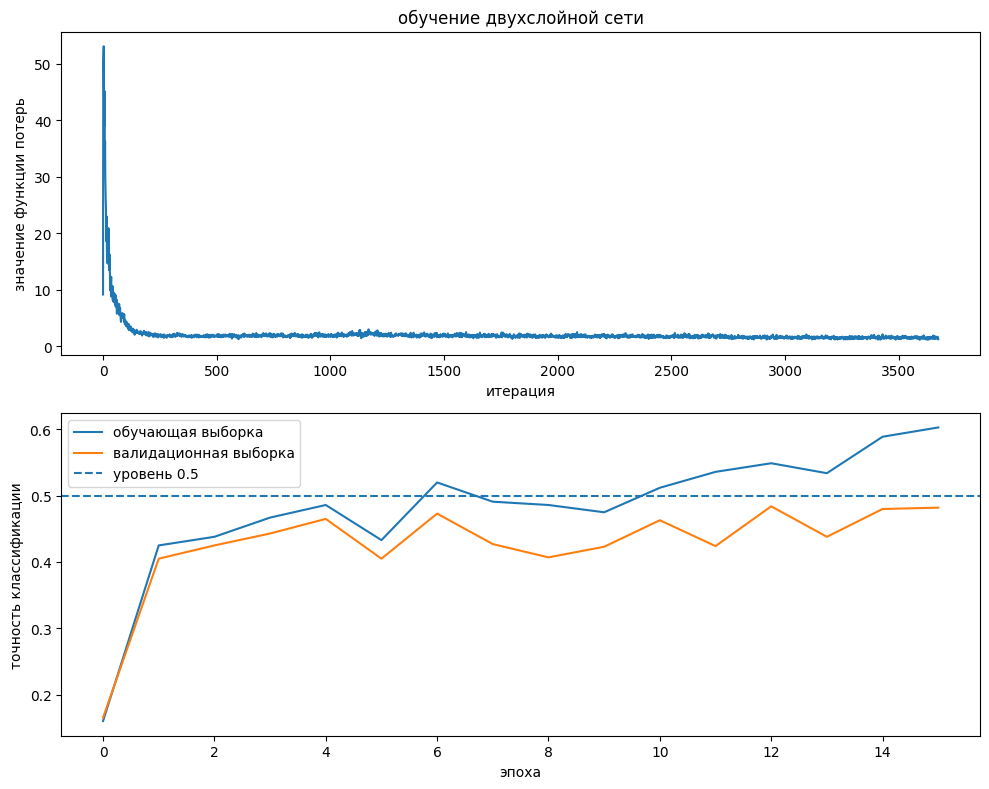

In [11]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)
plt.plot(solver_two.loss_history)
plt.title('обучение двухслойной сети')
plt.xlabel('итерация')
plt.ylabel('значение функции потерь')

plt.subplot(2, 1, 2)
plt.plot(solver_two.train_acc_history, label='обучающая выборка')
plt.plot(solver_two.val_acc_history, label='валидационная выборка')
plt.axhline(0.5, linestyle='--', label='уровень 0.5')
plt.xlabel('эпоха')
plt.ylabel('точность классификации')
plt.legend()

plt.tight_layout()
plt.show()

## сеть с произвольным числом слоев

In [12]:
np.random.seed(231)

n = 2
d = 15
h1 = 20
h2 = 30
c = 10

x = np.random.randn(n, d)
y = np.random.randint(c, size=n)

for reg in [0.0, 3.14]:
    model = fully_connected_net(
        [h1, h2],
        input_dim=d,
        num_classes=c,
        reg=reg,
        weight_scale=5e-2,
        dtype=np.float64
    )

    loss, grads = model.loss(x, y)

    print('регуляризация', reg, 'loss', loss)

    for name in sorted(grads):
        grad_num = eval_numerical_gradient(
            lambda value: model.loss(x, y)[0],
            model.params[name],
            verbose=False
        )

        print(name.lower(), 'ошибка', rel_error(grad_num, grads[name]))

регуляризация 0.0 loss 2.3004790897684924
w1 ошибка 1.4839894098713283e-07
w2 ошибка 2.21204793107852e-05
w3 ошибка 3.527252851540647e-07
b1 ошибка 5.376386228531692e-09
b2 ошибка 2.085654200257447e-09
b3 ошибка 5.7957243458479405e-11
регуляризация 3.14 loss 7.052114776533016
w1 ошибка 3.904541941902138e-09
w2 ошибка 6.86942277940646e-08
w3 ошибка 2.131129848945024e-08
b1 ошибка 1.4752427965311745e-08
b2 ошибка 1.7223751746766738e-09
b3 ошибка 1.5702714832602802e-10


## переобучение на 50 изображениях

In [13]:
np.random.seed(42)

small_data = {
    'x_train': data['x_train'][:50],
    'y_train': data['y_train'][:50],
    'x_val': data['x_val'],
    'y_val': data['y_val']
}

model_small = fully_connected_net(
    [100, 100],
    weight_scale=5e-2,
    dtype=np.float64
)

solver_small = solver_class(
    model_small,
    small_data,
    update_rule='adam',
    optim_config={'learning_rate': 1e-3},
    num_epochs=20,
    batch_size=25,
    print_every=20,
    verbose=True,
    num_train_samples=None
)

solver_small.train()

small_train_acc = solver_small.check_accuracy(
    small_data['x_train'],
    small_data['y_train']
)

print('точность на 50 изображениях', small_train_acc)

итерация 1 из 40 loss 25.797846
эпоха 0 из 20 точность train 0.32 точность val 0.119
эпоха 1 из 20 точность train 0.5 точность val 0.157
эпоха 2 из 20 точность train 0.62 точность val 0.168
эпоха 3 из 20 точность train 0.8 точность val 0.154
эпоха 4 из 20 точность train 0.76 точность val 0.142
эпоха 5 из 20 точность train 0.76 точность val 0.143
эпоха 6 из 20 точность train 0.88 точность val 0.146
эпоха 7 из 20 точность train 0.94 точность val 0.165
эпоха 8 из 20 точность train 0.96 точность val 0.159
эпоха 9 из 20 точность train 0.98 точность val 0.165
эпоха 10 из 20 точность train 1.0 точность val 0.163
итерация 21 из 40 loss 0.000354
эпоха 11 из 20 точность train 1.0 точность val 0.164
эпоха 12 из 20 точность train 1.0 точность val 0.158
эпоха 13 из 20 точность train 1.0 точность val 0.158
эпоха 14 из 20 точность train 0.98 точность val 0.159
эпоха 15 из 20 точность train 1.0 точность val 0.16
эпоха 16 из 20 точность train 1.0 точность val 0.159
эпоха 17 из 20 точность train 1.0 точ

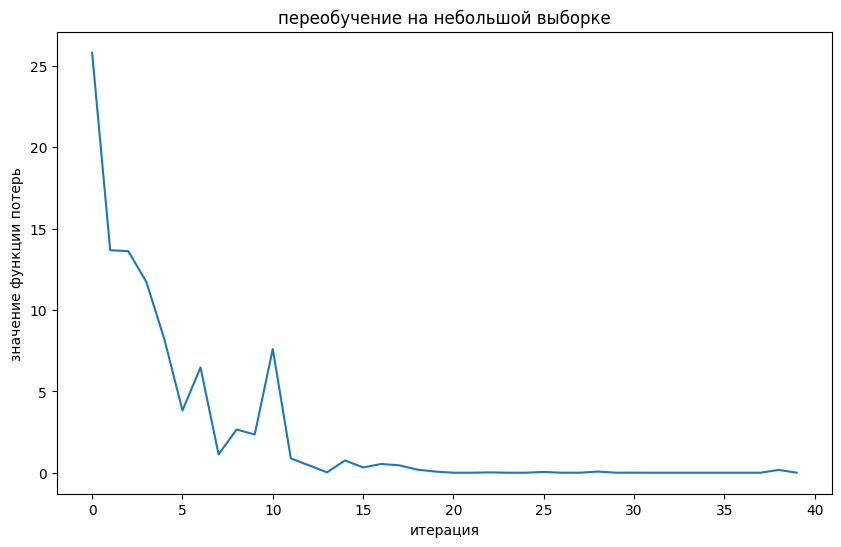

In [14]:
plt.plot(solver_small.loss_history)
plt.title('переобучение на небольшой выборке')
plt.xlabel('итерация')
plt.ylabel('значение функции потерь')
plt.show()

## сравнение sgd и momentum

In [15]:
n = 4
d = 5

w = np.linspace(-0.4, 0.6, num=n * d).reshape(n, d)
dw = np.linspace(-0.6, 0.4, num=n * d).reshape(n, d)
velocity = np.linspace(0.6, 0.9, num=n * d).reshape(n, d)

config = {
    'learning_rate': 1e-3,
    'velocity': velocity
}

next_w, config = sgd_momentum(w, dw, config)

print('среднее обновленных весов', next_w.mean())
print('средняя скорость', config['velocity'].mean())

среднее обновленных весов 0.7750999999999999
средняя скорость 0.6751


In [16]:
np.random.seed(42)

compare_data = {
    'x_train': data['x_train'][:4000],
    'y_train': data['y_train'][:4000],
    'x_val': data['x_val'],
    'y_val': data['y_val']
}

solvers_opt = {}

for rule in ['sgd', 'sgd_momentum']:
    model = fully_connected_net(
        [100, 100, 100, 100, 100],
        weight_scale=5e-2
    )

    current_solver = solver_class(
        model,
        compare_data,
        num_epochs=5,
        batch_size=100,
        update_rule=rule,
        optim_config={'learning_rate': 5e-3},
        verbose=False
    )

    current_solver.train()
    solvers_opt[rule] = current_solver

    print(rule, 'лучшая точность', current_solver.best_val_acc)

sgd лучшая точность 0.306
sgd_momentum лучшая точность 0.334


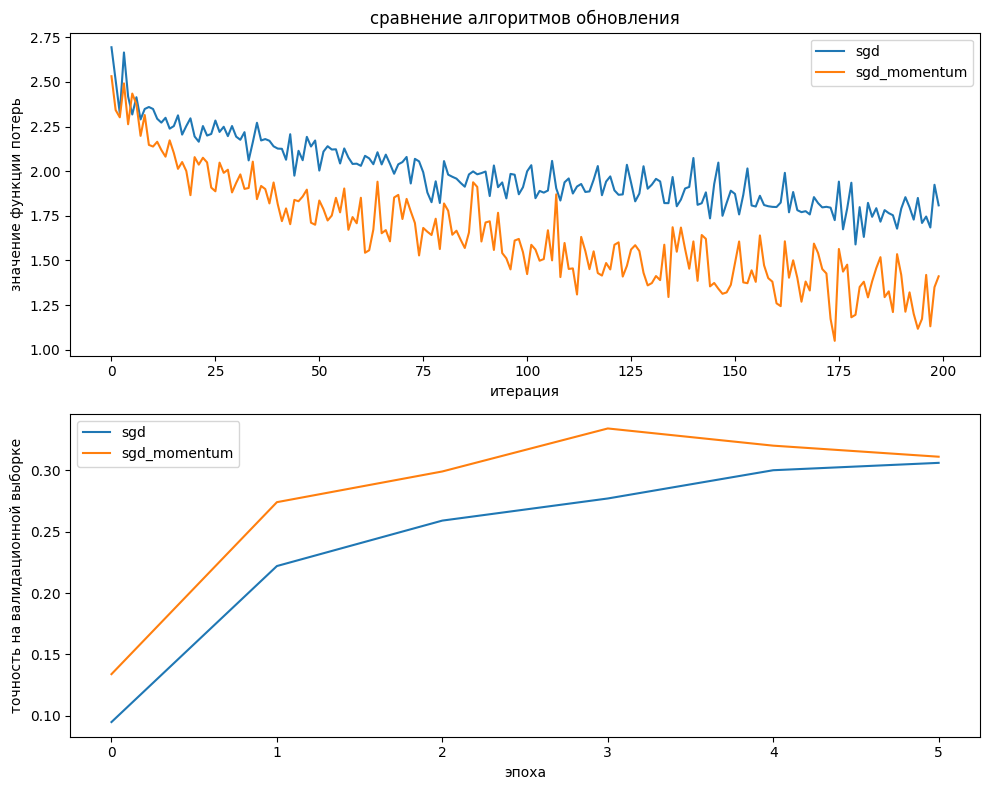

In [17]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)

for rule, current_solver in solvers_opt.items():
    plt.plot(
        current_solver.loss_history,
        label=rule
    )

plt.title('сравнение алгоритмов обновления')
plt.xlabel('итерация')
plt.ylabel('значение функции потерь')
plt.legend()

plt.subplot(2, 1, 2)

for rule, current_solver in solvers_opt.items():
    plt.plot(
        current_solver.val_acc_history,
        label=rule
    )

plt.xlabel('эпоха')
plt.ylabel('точность на валидационной выборке')
plt.legend()

plt.tight_layout()
plt.show()

## rmsprop и adam

In [18]:
n = 4
d = 5

w = np.linspace(-0.4, 0.6, num=n * d).reshape(n, d)
dw = np.linspace(-0.6, 0.4, num=n * d).reshape(n, d)
cache = np.linspace(0.6, 0.9, num=n * d).reshape(n, d)

config = {
    'learning_rate': 1e-2,
    'cache': cache
}

next_w, config = rmsprop(w, dw, config)

print('среднее весов rmsprop', next_w.mean())
print('среднее cache', config['cache'].mean())

среднее весов rmsprop 0.10138123757814403
среднее cache 0.7435210526315787


In [19]:
n = 4
d = 5

w = np.linspace(-0.4, 0.6, num=n * d).reshape(n, d)
dw = np.linspace(-0.6, 0.4, num=n * d).reshape(n, d)
m = np.linspace(0.6, 0.9, num=n * d).reshape(n, d)
v = np.linspace(0.7, 0.5, num=n * d).reshape(n, d)

config = {
    'learning_rate': 1e-2,
    'm': m,
    'v': v,
    't': 5
}

next_w, config = adam(w, dw, config)

print('среднее весов adam', next_w.mean())
print('номер шага', config['t'])

среднее весов adam 0.09856415414862034
номер шага 6


In [20]:
np.random.seed(42)

solvers_adaptive = {}

for rule in ['rmsprop', 'adam']:
    model = fully_connected_net(
        [100, 100, 100],
        weight_scale=5e-2
    )

    current_solver = solver_class(
        model,
        compare_data,
        num_epochs=5,
        batch_size=100,
        update_rule=rule,
        optim_config={'learning_rate': 1e-3},
        verbose=False
    )

    current_solver.train()
    solvers_adaptive[rule] = current_solver

    print(rule, 'лучшая точность', current_solver.best_val_acc)

rmsprop лучшая точность 0.319
adam лучшая точность 0.374


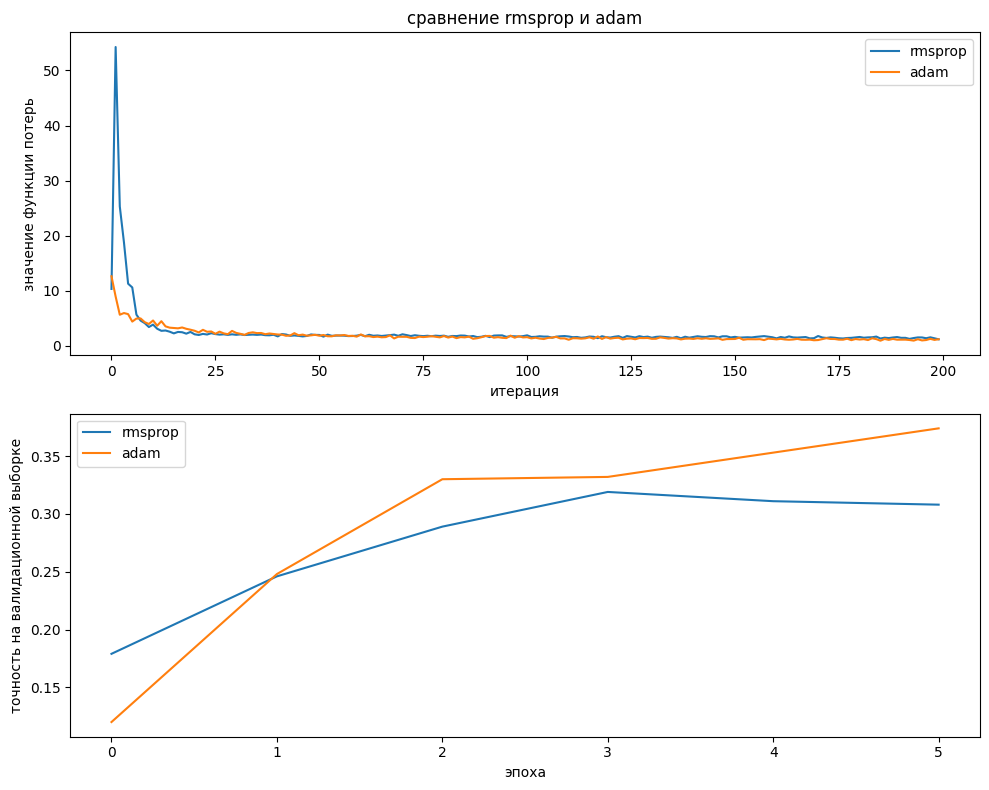

In [21]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)

for rule, current_solver in solvers_adaptive.items():
    plt.plot(
        current_solver.loss_history,
        label=rule
    )

plt.title('сравнение rmsprop и adam')
plt.xlabel('итерация')
plt.ylabel('значение функции потерь')
plt.legend()

plt.subplot(2, 1, 2)

for rule, current_solver in solvers_adaptive.items():
    plt.plot(
        current_solver.val_acc_history,
        label=rule
    )

plt.xlabel('эпоха')
plt.ylabel('точность на валидационной выборке')
plt.legend()

plt.tight_layout()
plt.show()

## batch normalization

In [22]:
np.random.seed(231)

n = 200
d1 = 50
d2 = 60
d3 = 3

x = np.random.randn(n, d1)
w1 = np.random.randn(d1, d2)
w2 = np.random.randn(d2, d3)

a = np.maximum(0, x.dot(w1)).dot(w2)

print('до нормализации')
print_mean_std(a)

gamma = np.ones(d3)
beta = np.zeros(d3)

a_norm, _ = batchnorm_forward(
    a,
    gamma,
    beta,
    {'mode': 'train'}
)

print('после нормализации')
print_mean_std(a_norm)

до нормализации
среднее [ -2.3814598  -13.18038246   1.91780462]
стандартное отклонение [27.18502186 34.21455511 37.68611762]
после нормализации
среднее [ 3.77475828e-17  6.16173779e-17 -3.42781359e-17]
стандартное отклонение [0.99999999 1.         1.        ]


In [23]:
np.random.seed(231)

n = 4
d = 5

x = 5 * np.random.randn(n, d) + 12
gamma = np.random.randn(d)
beta = np.random.randn(d)
dout = np.random.randn(n, d)

bn_param = {'mode': 'train'}

fx = lambda value: batchnorm_forward(value, gamma, beta, bn_param)[0]
fg = lambda value: batchnorm_forward(x, value, beta, bn_param)[0]
fb = lambda value: batchnorm_forward(x, gamma, value, bn_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
dgamma_num = eval_numerical_gradient_array(fg, gamma.copy(), dout)
dbeta_num = eval_numerical_gradient_array(fb, beta.copy(), dout)

_, cache = batchnorm_forward(
    x,
    gamma,
    beta,
    bn_param
)

dx, dgamma, dbeta = batchnorm_backward(
    dout,
    cache
)

print('ошибка dx', rel_error(dx_num, dx))
print('ошибка dgamma', rel_error(dgamma_num, dgamma))
print('ошибка dbeta', rel_error(dbeta_num, dbeta))

ошибка dx 1.667461836271981e-09
ошибка dgamma 7.417225040694815e-13
ошибка dbeta 2.379446949959628e-12


## влияние batch normalization

In [24]:
np.random.seed(42)

bn_data = {
    'x_train': data['x_train'][:1000],
    'y_train': data['y_train'][:1000],
    'x_val': data['x_val'],
    'y_val': data['y_val']
}

hidden_dims = [100, 100, 100, 100, 100]

model_bn = fully_connected_net(
    hidden_dims,
    weight_scale=2e-2,
    normalization='batchnorm'
)

model_plain = fully_connected_net(
    hidden_dims,
    weight_scale=2e-2
)

solver_bn = solver_class(
    model_bn,
    bn_data,
    num_epochs=10,
    batch_size=50,
    update_rule='adam',
    optim_config={'learning_rate': 1e-3},
    verbose=False
)

solver_plain = solver_class(
    model_plain,
    bn_data,
    num_epochs=10,
    batch_size=50,
    update_rule='adam',
    optim_config={'learning_rate': 1e-3},
    verbose=False
)

solver_bn.train()
solver_plain.train()

print('лучшая точность с нормализацией', solver_bn.best_val_acc)
print('лучшая точность без нормализации', solver_plain.best_val_acc)

лучшая точность с нормализацией 0.333
лучшая точность без нормализации 0.327


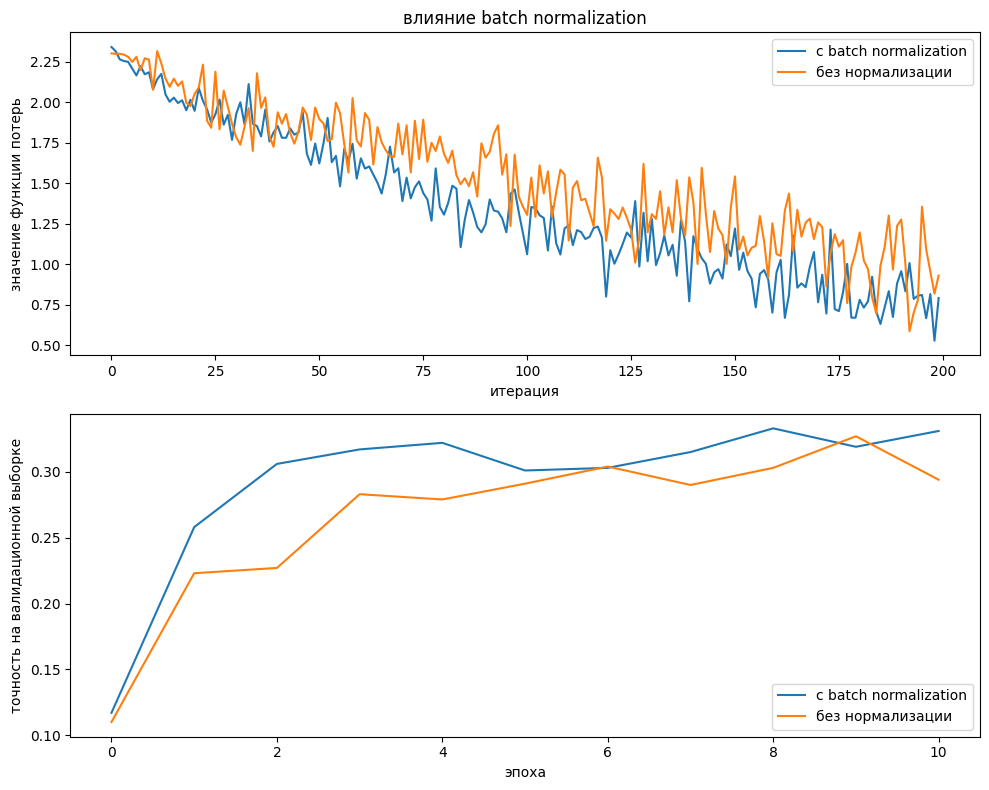

In [25]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)
plt.plot(
    solver_bn.loss_history,
    label='с batch normalization'
)
plt.plot(
    solver_plain.loss_history,
    label='без нормализации'
)
plt.title('влияние batch normalization')
plt.xlabel('итерация')
plt.ylabel('значение функции потерь')
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(
    solver_bn.val_acc_history,
    label='с batch normalization'
)
plt.plot(
    solver_plain.val_acc_history,
    label='без нормализации'
)
plt.xlabel('эпоха')
plt.ylabel('точность на валидационной выборке')
plt.legend()

plt.tight_layout()
plt.show()

## размер мини батча

In [26]:
batch_sizes = [25, 50, 100]
batch_solvers = {}

for batch_size in batch_sizes:
    model = fully_connected_net(
        hidden_dims,
        weight_scale=2e-2,
        normalization='batchnorm'
    )

    current_solver = solver_class(
        model,
        bn_data,
        num_epochs=6,
        batch_size=batch_size,
        update_rule='adam',
        optim_config={'learning_rate': 3e-4},
        verbose=False
    )

    current_solver.train()
    batch_solvers[batch_size] = current_solver

    print('размер батча', batch_size, 'точность', current_solver.best_val_acc)

размер батча 25 точность 0.327
размер батча 50 точность 0.324
размер батча 100 точность 0.325


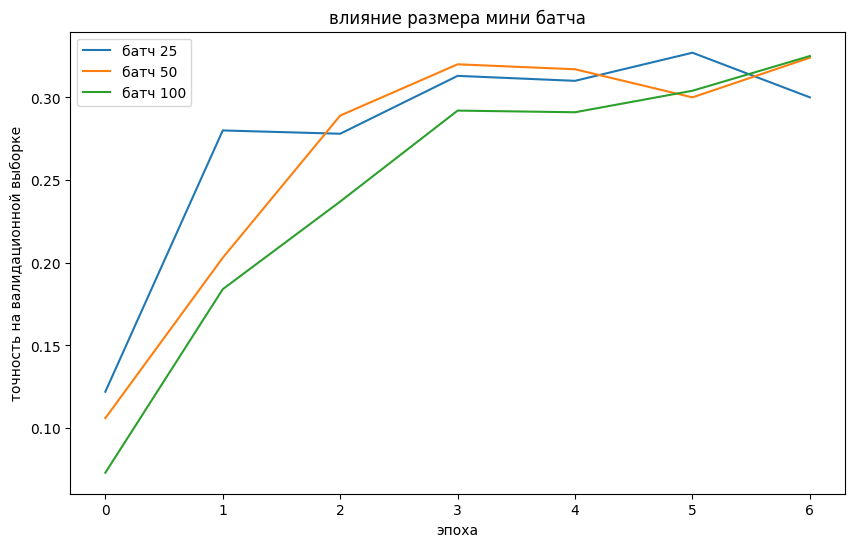

In [27]:
for batch_size, current_solver in batch_solvers.items():
    plt.plot(
        current_solver.val_acc_history,
        label='батч ' + str(batch_size)
    )

plt.title('влияние размера мини батча')
plt.xlabel('эпоха')
plt.ylabel('точность на валидационной выборке')
plt.legend()
plt.show()

## dropout

In [28]:
np.random.seed(231)

x = np.random.randn(500, 500) + 10

for p in [0.25, 0.4, 0.7]:
    out, _ = dropout_forward(
        x,
        {'mode': 'train', 'p': p}
    )

    out_test, _ = dropout_forward(
        x,
        {'mode': 'test', 'p': p}
    )

    print('вероятность сохранения', p)
    print('среднее входа', x.mean())
    print('среднее на обучении', out.mean())
    print('среднее на тесте', out_test.mean())
    print('доля нулей на обучении', (out == 0).mean())

вероятность сохранения 0.25
среднее входа 10.0002078784775
среднее на обучении 10.014059116977283
среднее на тесте 10.0002078784775
доля нулей на обучении 0.749784
вероятность сохранения 0.4
среднее входа 10.0002078784775
среднее на обучении 9.977917658761159
среднее на тесте 10.0002078784775
доля нулей на обучении 0.600796
вероятность сохранения 0.7
среднее входа 10.0002078784775
среднее на обучении 9.987811912159428
среднее на тесте 10.0002078784775
доля нулей на обучении 0.30074


In [29]:
np.random.seed(231)

x = np.random.randn(10, 10) + 10
dout = np.random.randn(*x.shape)

dropout_param = {
    'mode': 'train',
    'p': 0.8,
    'seed': 123
}

out, cache = dropout_forward(
    x,
    dropout_param
)

dx = dropout_backward(
    dout,
    cache
)

dx_num = eval_numerical_gradient_array(
    lambda value: dropout_forward(value, dropout_param)[0],
    x,
    dout
)

print('ошибка dropout', rel_error(dx, dx_num))

ошибка dropout 5.445612718272284e-11


## влияние dropout

In [30]:
np.random.seed(42)

dropout_data = {
    'x_train': data['x_train'][:500],
    'y_train': data['y_train'][:500],
    'x_val': data['x_val'],
    'y_val': data['y_val']
}

dropout_values = [1.0, 0.75]
dropout_solvers = {}

for keep_prob in dropout_values:
    model = fully_connected_net(
        [500],
        dropout=keep_prob,
        weight_scale=1e-2
    )

    current_solver = solver_class(
        model,
        dropout_data,
        num_epochs=20,
        batch_size=100,
        update_rule='adam',
        optim_config={'learning_rate': 5e-4},
        verbose=False
    )

    current_solver.train()
    dropout_solvers[keep_prob] = current_solver

    print('вероятность сохранения', keep_prob, 'точность', current_solver.best_val_acc)

вероятность сохранения 1.0 точность 0.32
вероятность сохранения 0.75 точность 0.318


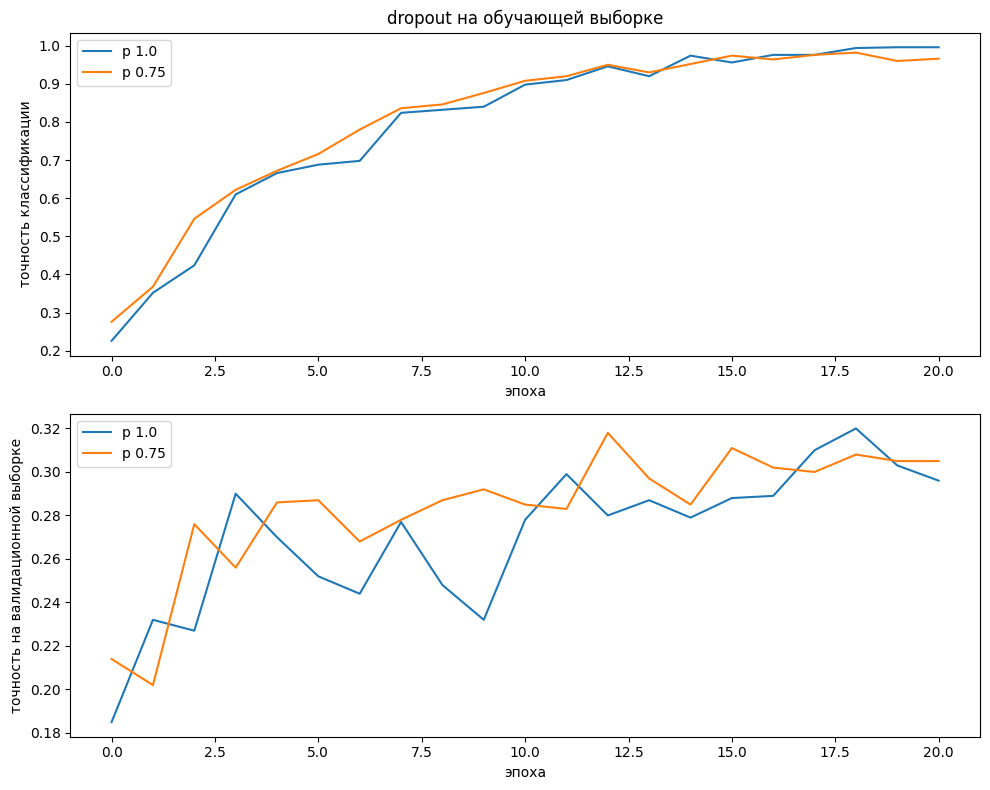

In [31]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)

for keep_prob, current_solver in dropout_solvers.items():
    plt.plot(
        current_solver.train_acc_history,
        label='p ' + str(keep_prob)
    )

plt.title('dropout на обучающей выборке')
plt.xlabel('эпоха')
plt.ylabel('точность классификации')
plt.legend()

plt.subplot(2, 1, 2)

for keep_prob, current_solver in dropout_solvers.items():
    plt.plot(
        current_solver.val_acc_history,
        label='p ' + str(keep_prob)
    )

plt.xlabel('эпоха')
plt.ylabel('точность на валидационной выборке')
plt.legend()

plt.tight_layout()
plt.show()

## лучшая полносвязная сеть

In [32]:
np.random.seed(42)

best_model = fully_connected_net(
    [512, 256, 128],
    normalization='batchnorm',
    dropout=0.8,
    weight_scale=2e-2,
    reg=1e-3
)

best_solver = solver_class(
    best_model,
    data,
    update_rule='adam',
    optim_config={'learning_rate': 1e-3},
    lr_decay=0.95,
    num_epochs=15,
    batch_size=200,
    print_every=200,
    verbose=True
)

best_solver.train()

val_acc = best_solver.check_accuracy(
    data['x_val'],
    data['y_val'],
    num_samples=None
)

test_acc = best_solver.check_accuracy(
    data['x_test'],
    data['y_test'],
    num_samples=None
)

print('точность на валидационной выборке', val_acc)
print('точность на тестовой выборке', test_acc)

итерация 1 из 3675 loss 2.652749
эпоха 0 из 15 точность train 0.202 точность val 0.211
итерация 201 из 3675 loss 1.779001
эпоха 1 из 15 точность train 0.458 точность val 0.466
итерация 401 из 3675 loss 1.608143
эпоха 2 из 15 точность train 0.478 точность val 0.497
итерация 601 из 3675 loss 1.498847
эпоха 3 из 15 точность train 0.522 точность val 0.508
итерация 801 из 3675 loss 1.517189
эпоха 4 из 15 точность train 0.537 точность val 0.513
итерация 1001 из 3675 loss 1.442727
итерация 1201 из 3675 loss 1.530596
эпоха 5 из 15 точность train 0.573 точность val 0.521
итерация 1401 из 3675 loss 1.57548
эпоха 6 из 15 точность train 0.54 точность val 0.513
итерация 1601 из 3675 loss 1.49539
эпоха 7 из 15 точность train 0.586 точность val 0.533
итерация 1801 из 3675 loss 1.542546
эпоха 8 из 15 точность train 0.547 точность val 0.543
итерация 2001 из 3675 loss 1.483203
итерация 2201 из 3675 loss 1.365859
эпоха 9 из 15 точность train 0.596 точность val 0.545
итерация 2401 из 3675 loss 1.32463
эпо

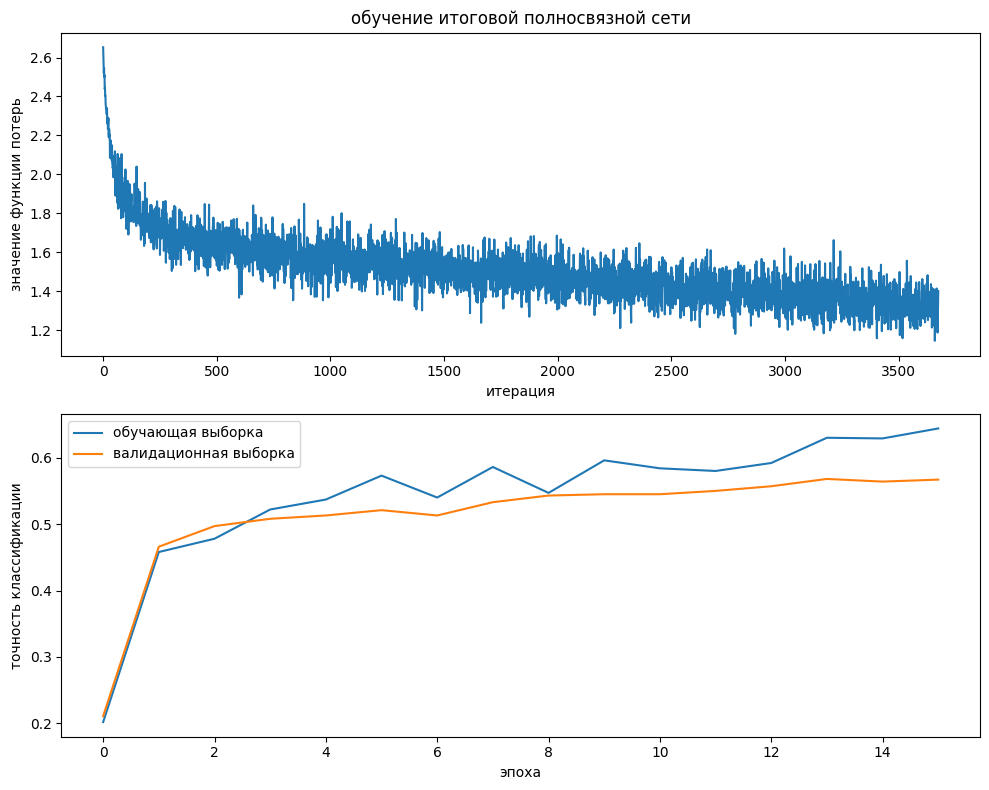

In [33]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)
plt.plot(best_solver.loss_history)
plt.title('обучение итоговой полносвязной сети')
plt.xlabel('итерация')
plt.ylabel('значение функции потерь')

plt.subplot(2, 1, 2)
plt.plot(
    best_solver.train_acc_history,
    label='обучающая выборка'
)
plt.plot(
    best_solver.val_acc_history,
    label='валидационная выборка'
)
plt.xlabel('эпоха')
plt.ylabel('точность классификации')
plt.legend()

plt.tight_layout()
plt.show()

## сверточный слой

In [34]:
x_shape = (2, 3, 4, 4)
w_shape = (3, 3, 4, 4)

x = np.linspace(
    -0.1,
    0.5,
    num=np.prod(x_shape)
).reshape(x_shape)

w = np.linspace(
    -0.2,
    0.3,
    num=np.prod(w_shape)
).reshape(w_shape)

b = np.linspace(-0.1, 0.2, num=3)

conv_param = {
    'stride': 2,
    'pad': 1
}

out, _ = conv_forward_naive(
    x,
    w,
    b,
    conv_param
)

correct_out = np.array([
    [
        [
            [-0.08759809, -0.10987781],
            [-0.18387192, -0.21092160]
        ],
        [
            [0.21027089, 0.21661097],
            [0.22847626, 0.23004637]
        ],
        [
            [0.50813986, 0.54309974],
            [0.64082444, 0.67101435]
        ]
    ],
    [
        [
            [-0.98053589, -1.03143541],
            [-1.19128892, -1.24695841]
        ],
        [
            [0.69108355, 0.66880383],
            [0.59480972, 0.56776003]
        ],
        [
            [2.36270298, 2.36904306],
            [2.38090835, 2.38247847]
        ]
    ]
])

print('ошибка прямой свертки', rel_error(out, correct_out))

ошибка прямой свертки 2.2121476417505994e-08


In [35]:
np.random.seed(231)

x = np.random.randn(4, 3, 5, 5)
w = np.random.randn(2, 3, 3, 3)
b = np.random.randn(2)
dout = np.random.randn(4, 2, 5, 5)

conv_param = {
    'stride': 1,
    'pad': 1
}

dx_num = eval_numerical_gradient_array(
    lambda value: conv_forward_naive(value, w, b, conv_param)[0],
    x,
    dout
)

dw_num = eval_numerical_gradient_array(
    lambda value: conv_forward_naive(x, value, b, conv_param)[0],
    w,
    dout
)

db_num = eval_numerical_gradient_array(
    lambda value: conv_forward_naive(x, w, value, conv_param)[0],
    b,
    dout
)

out, cache = conv_forward_naive(
    x,
    w,
    b,
    conv_param
)

dx, dw, db = conv_backward_naive(
    dout,
    cache
)

print('ошибка dx', rel_error(dx, dx_num))
print('ошибка dw', rel_error(dw, dw_num))
print('ошибка db', rel_error(db, db_num))

ошибка dx 1.159803161159293e-08
ошибка dw 2.2471264748452487e-10
ошибка db 3.37264006649648e-11


## max pooling

In [36]:
x_shape = (2, 3, 4, 4)

x = np.linspace(
    -0.3,
    0.4,
    num=np.prod(x_shape)
).reshape(x_shape)

pool_param = {
    'pool_width': 2,
    'pool_height': 2,
    'stride': 2
}

out, _ = max_pool_forward_naive(
    x,
    pool_param
)

print('форма после pooling', out.shape)
print('первое значение', out[0, 0, 0, 0])

форма после pooling (2, 3, 2, 2)
первое значение -0.2631578947368421


In [37]:
np.random.seed(231)

x = np.random.randn(3, 2, 8, 8)
dout = np.random.randn(3, 2, 4, 4)

pool_param = {
    'pool_height': 2,
    'pool_width': 2,
    'stride': 2
}

dx_num = eval_numerical_gradient_array(
    lambda value: max_pool_forward_naive(value, pool_param)[0],
    x,
    dout
)

out, cache = max_pool_forward_naive(
    x,
    pool_param
)

dx = max_pool_backward_naive(
    dout,
    cache
)

print('ошибка pooling', rel_error(dx, dx_num))

ошибка pooling 3.27562514223145e-12


## сравнение обычной и быстрой свертки

In [38]:
np.random.seed(231)

x = np.random.randn(20, 3, 31, 31)
w = np.random.randn(12, 3, 3, 3)
b = np.random.randn(12)

conv_param = {
    'stride': 2,
    'pad': 1
}

start = time.time()
out_naive, _ = conv_forward_naive(
    x,
    w,
    b,
    conv_param
)
time_naive = time.time() - start

start = time.time()
out_fast, _ = conv_forward_fast(
    x,
    w,
    b,
    conv_param
)
time_fast = time.time() - start

print('время обычной свертки', time_naive)
print('время быстрой свертки', time_fast)
print('ускорение', time_naive / time_fast)
print('разница результатов', rel_error(out_naive, out_fast))

время обычной свертки 0.570439338684082
время быстрой свертки 0.0012938976287841797
ускорение 440.86898839137643
разница результатов 5.2002837783872185e-12


## трехслойная сверточная сеть

In [39]:
np.random.seed(231)

model = three_layer_conv_net()

x = np.random.randn(50, 3, 32, 32)
y = np.random.randint(10, size=50)

loss, grads = model.loss(x, y)

print('начальный loss без регуляризации', loss)

model.reg = 0.5
loss_reg, grads = model.loss(x, y)

print('начальный loss с регуляризацией', loss_reg)

начальный loss без регуляризации 2.3025821830331865
начальный loss с регуляризацией 2.5082647587358537


In [40]:
np.random.seed(231)

num_inputs = 2
input_dim = (3, 16, 16)
num_classes = 10

x = np.random.randn(
    num_inputs,
    *input_dim
)

y = np.random.randint(
    num_classes,
    size=num_inputs
)

model = three_layer_conv_net(
    num_filters=3,
    filter_size=3,
    input_dim=input_dim,
    hidden_dim=7,
    dtype=np.float64
)

loss, grads = model.loss(x, y)

for name in sorted(grads):
    grad_num = eval_numerical_gradient(
        lambda value: model.loss(x, y)[0],
        model.params[name],
        verbose=False,
        h=1e-6
    )

    print(name.lower(), 'ошибка', rel_error(grad_num, grads[name]))

w1 ошибка 0.0001380104081398071
w2 ошибка 0.018227230049163972
w3 ошибка 0.00030640485077426547
b1 ошибка 3.477651903650915e-05
b2 ошибка 0.002516374773892462
b3 ошибка 7.945660309666462e-10


## переобучение сверточной сети

In [41]:
np.random.seed(42)

cnn_small_data = {
    'x_train': data['x_train'][:100],
    'y_train': data['y_train'][:100],
    'x_val': data['x_val'],
    'y_val': data['y_val']
}

cnn_small = three_layer_conv_net(
    weight_scale=1e-2,
    hidden_dim=100,
    num_filters=16
)

cnn_small_solver = solver_class(
    cnn_small,
    cnn_small_data,
    num_epochs=15,
    batch_size=50,
    update_rule='adam',
    optim_config={'learning_rate': 1e-3},
    verbose=True,
    print_every=5,
    num_train_samples=None
)

cnn_small_solver.train()

cnn_small_train = cnn_small_solver.check_accuracy(
    cnn_small_data['x_train'],
    cnn_small_data['y_train'],
    num_samples=None
)

cnn_small_val = cnn_small_solver.check_accuracy(
    cnn_small_data['x_val'],
    cnn_small_data['y_val'],
    num_samples=None
)

print('точность на обучающей выборке', cnn_small_train)
print('точность на валидационной выборке', cnn_small_val)

итерация 1 из 30 loss 2.294425
эпоха 0 из 15 точность train 0.22 точность val 0.101
эпоха 1 из 15 точность train 0.21 точность val 0.103
эпоха 2 из 15 точность train 0.25 точность val 0.162
итерация 6 из 30 loss 1.930487
эпоха 3 из 15 точность train 0.51 точность val 0.187
эпоха 4 из 15 точность train 0.51 точность val 0.179
эпоха 5 из 15 точность train 0.57 точность val 0.199
итерация 11 из 30 loss 1.249817
эпоха 6 из 15 точность train 0.63 точность val 0.192
эпоха 7 из 15 точность train 0.73 точность val 0.2
итерация 16 из 30 loss 0.636238
эпоха 8 из 15 точность train 0.83 точность val 0.223
эпоха 9 из 15 точность train 0.88 точность val 0.237
эпоха 10 из 15 точность train 0.92 точность val 0.237
итерация 21 из 30 loss 0.178203
эпоха 11 из 15 точность train 0.95 точность val 0.224
эпоха 12 из 15 точность train 0.98 точность val 0.229
итерация 26 из 30 loss 0.073262
эпоха 13 из 15 точность train 0.99 точность val 0.225
эпоха 14 из 15 точность train 0.99 точность val 0.222
эпоха 15 из 

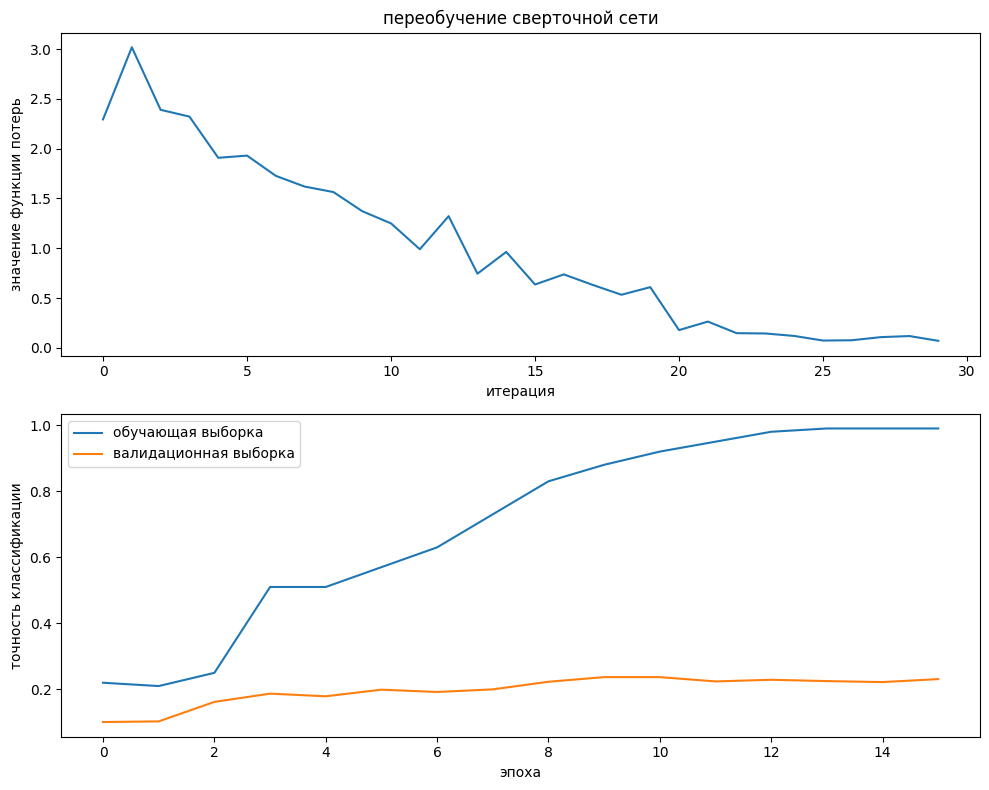

In [42]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)
plt.plot(cnn_small_solver.loss_history)
plt.title('переобучение сверточной сети')
plt.xlabel('итерация')
plt.ylabel('значение функции потерь')

plt.subplot(2, 1, 2)
plt.plot(
    cnn_small_solver.train_acc_history,
    label='обучающая выборка'
)
plt.plot(
    cnn_small_solver.val_acc_history,
    label='валидационная выборка'
)
plt.xlabel('эпоха')
plt.ylabel('точность классификации')
plt.legend()

plt.tight_layout()
plt.show()

## обучение сверточной сети на полном наборе

In [43]:
np.random.seed(42)

cnn_model = three_layer_conv_net(
    weight_scale=1e-3,
    hidden_dim=300,
    num_filters=24,
    reg=1e-3
)

cnn_solver = solver_class(
    cnn_model,
    data,
    num_epochs=1,
    batch_size=50,
    update_rule='adam',
    optim_config={'learning_rate': 1e-3},
    verbose=True,
    print_every=100
)

cnn_solver.train()

cnn_train_acc = cnn_solver.check_accuracy(
    data['x_train'],
    data['y_train'],
    num_samples=2000
)

cnn_val_acc = cnn_solver.check_accuracy(
    data['x_val'],
    data['y_val'],
    num_samples=None
)

print('точность cnn на обучающей выборке', cnn_train_acc)
print('точность cnn на валидационной выборке', cnn_val_acc)

итерация 1 из 980 loss 2.30353
эпоха 0 из 1 точность train 0.107 точность val 0.079
итерация 101 из 980 loss 1.73432
итерация 201 из 980 loss 1.325164
итерация 301 из 980 loss 2.144879
итерация 401 из 980 loss 1.869349
итерация 501 из 980 loss 1.656373
итерация 601 из 980 loss 1.532062
итерация 701 из 980 loss 1.213133
итерация 801 из 980 loss 1.218726
итерация 901 из 980 loss 1.442487
эпоха 1 из 1 точность train 0.482 точность val 0.484
точность cnn на обучающей выборке 0.4955
точность cnn на валидационной выборке 0.484


## фильтры первого слоя

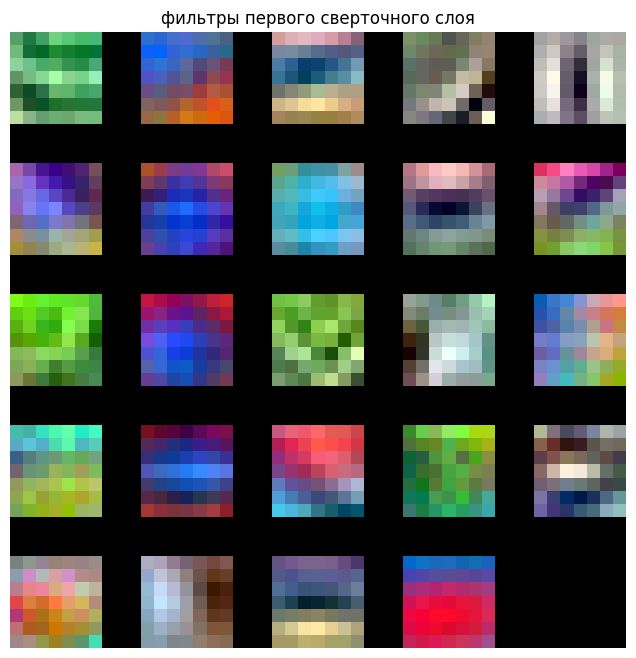

In [44]:
filters = cnn_model.params['W1'].transpose(0, 2, 3, 1)
grid = visualize_grid(filters, padding=3)

plt.figure(figsize=(8, 8))
plt.imshow(grid.astype('uint8'))
plt.title('фильтры первого сверточного слоя')
plt.axis('off')
plt.show()

## вывод

в лабораторной работе были реализованы основные операции для полносвязных и сверточных нейронных сетей. корректность прямого и обратного проходов проверяется численными градиентами. batch normalization позволяет стабилизировать обучение глубокой сети, а dropout уменьшает переобучение за счет случайного отключения части активаций во время обучения. адаптивные методы обновления весов позволяют быстрее подобрать подходящий шаг для разных параметров. сверточная сеть использует локальные фильтры и поэтому лучше подходит для изображений, чем обычная полносвязная модель. итоговые значения точности следует оценивать по результатам выполненных ячеек, так как они зависят от конкретного запуска и случайной инициализации.
